Device: cpu
Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.

TASK 1: Dataset loaded
                                              review sentiment  label
0  one of the other reviewers has mentioned that ...  positive      1
1  a wonderful little production the filming tech...  positive      1
2  i thought this was a wonderful way to spend ti...  positive      1
3  basically there s a family where a little boy ...  negative      0
4  petter mattei s love in the time of money is a...  positive      1
Dataset shape: (49582, 3)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64

TASK 2: LSTM model created
LSTMModel(
  (embedding): Embedding(20000, 64, padding_idx=0)
  (lstm): LSTM(64, 64, batch_first=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)
Epoch 1/5 | Train Loss: 0.6729 | Validation Loss: 0.6806
Epoch 2/5 | Train Loss: 0.6061 | Validation Loss: 0.6570
Epoch 3/5 

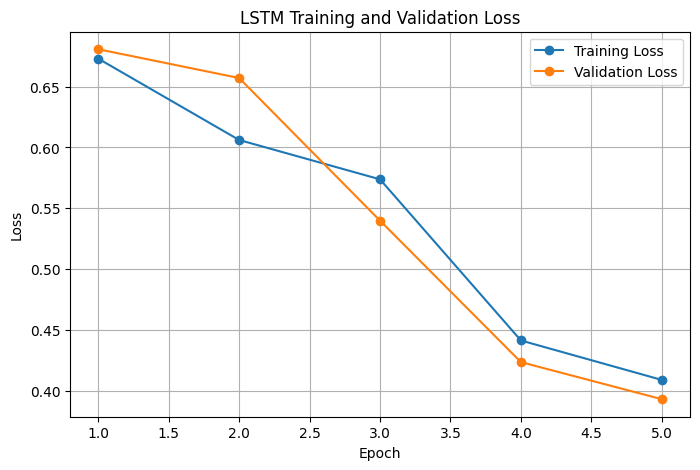

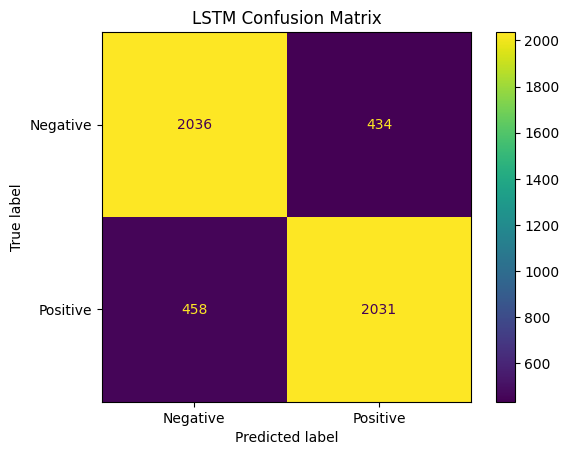


TASK 6: MODEL COMPARISON
   Metric   LSTM  TF-IDF + Logistic Regression
 Accuracy 0.8201                        0.8955
Precision 0.8239                        0.8866
   Recall 0.8160                        0.9080
 F1-score 0.8199                        0.8972


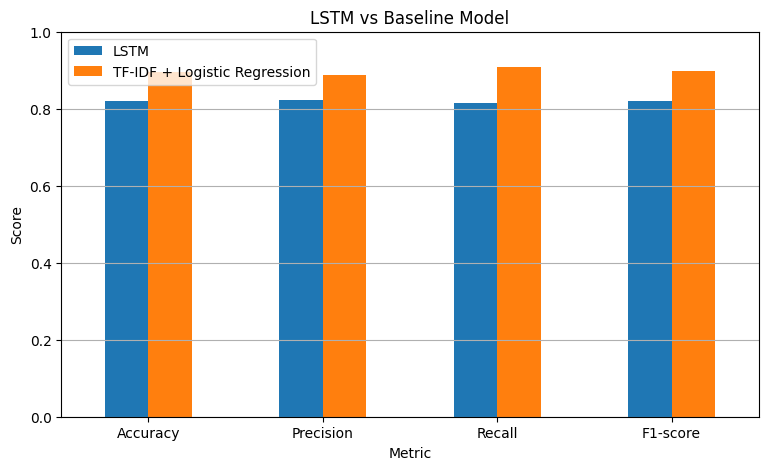


Sample review: The movie was excellent and the acting was amazing!
Predicted sentiment: Positive
Positive probability: 0.929

Lab 13 completed successfully.


In [ ]:
# LAB 13: IMPLEMENTING LSTM FOR SENTIMENT ANALYSIS
# Dataset: IMDB Movie Reviews (50K)

# Install and import libraries
!pip -q install kagglehub

import os
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import kagglehub
import torch
import torch.nn as nn

from collections import Counter
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Set random seeds
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# --------------------------------------------------
# TASK 1: DOWNLOAD AND PREPROCESS DATASET
# --------------------------------------------------

path = kagglehub.dataset_download(
    "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews"
)

csv_path = os.path.join(path, "IMDB Dataset.csv")
df = pd.read_csv(csv_path)

df = df.dropna(subset=["review", "sentiment"])
df = df.drop_duplicates(subset=["review"])

def preprocess(text):
    text = re.sub(r"<.*?>", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip().lower()

df["review"] = df["review"].apply(preprocess)
df["label"] = df["sentiment"].str.lower().map({
    "negative": 0,
    "positive": 1
})

df = df.dropna(subset=["label"])
df["label"] = df["label"].astype(int)

print("\nTASK 1: Dataset loaded")
print(df.head())
print("Dataset shape:", df.shape)
print(df["sentiment"].value_counts())

X = df["review"].tolist()
y = df["label"].tolist()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5,
    random_state=42, stratify=y_temp
)

# --------------------------------------------------
# TASK 2: IMPLEMENT PYTORCH LSTM ARCHITECTURE
# --------------------------------------------------

MAX_VOCAB = 20000
MAX_LEN = 200

counter = Counter(
    word for review in X_train for word in review.split()
)

vocab = {"<PAD>": 0, "<UNK>": 1}

for word, _ in counter.most_common(MAX_VOCAB - 2):
    vocab[word] = len(vocab)

def encode(text):
    tokens = text.split()[:MAX_LEN]
    ids = [vocab.get(word, 1) for word in tokens]
    length = max(1, len(ids))
    ids += [0] * (MAX_LEN - len(ids))
    return ids, length

class ReviewDataset(Dataset):
    def __init__(self, texts, labels):
        self.texts = texts
        self.labels = labels

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        ids, length = encode(self.texts[idx])
        return (
            torch.tensor(ids, dtype=torch.long),
            torch.tensor(length, dtype=torch.long),
            torch.tensor(self.labels[idx], dtype=torch.float32)
        )

class LSTMModel(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.embedding = nn.Embedding(
            vocab_size, 64, padding_idx=0
        )
        self.lstm = nn.LSTM(
            input_size=64, hidden_size=64,
            batch_first=True
        )
        self.dropout = nn.Dropout(0.3)
        self.fc = nn.Linear(64, 1)

    def forward(self, x, lengths):
        x = self.embedding(x)

        packed = nn.utils.rnn.pack_padded_sequence(
            x, lengths.cpu(), batch_first=True,
            enforce_sorted=False
        )

        _, (hidden, _) = self.lstm(packed)
        return self.fc(self.dropout(hidden[-1])).squeeze(1)

train_loader = DataLoader(
    ReviewDataset(X_train, y_train),
    batch_size=64, shuffle=True
)

val_loader = DataLoader(
    ReviewDataset(X_val, y_val), batch_size=64
)

test_loader = DataLoader(
    ReviewDataset(X_test, y_test), batch_size=64
)

model = LSTMModel(len(vocab)).to(device)
criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

print("\nTASK 2: LSTM model created")
print(model)

# --------------------------------------------------
# TASK 3: TRAIN THE MODEL
# --------------------------------------------------

EPOCHS = 5
train_losses = []
val_losses = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for reviews, lengths, labels in train_loader:
        reviews = reviews.to(device)
        lengths = lengths.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(reviews, lengths)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * labels.size(0)

    train_loss = total_loss / len(train_loader.dataset)
    train_losses.append(train_loss)

    model.eval()
    val_total = 0

    with torch.no_grad():
        for reviews, lengths, labels in val_loader:
            reviews = reviews.to(device)
            lengths = lengths.to(device)
            labels = labels.to(device)

            outputs = model(reviews, lengths)
            loss = criterion(outputs, labels)
            val_total += loss.item() * labels.size(0)

    val_loss = val_total / len(val_loader.dataset)
    val_losses.append(val_loss)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Loss: {val_loss:.4f}"
    )

# --------------------------------------------------
# TASK 4: EVALUATE MODEL
# --------------------------------------------------

model.eval()
y_true = []
y_pred = []

with torch.no_grad():
    for reviews, lengths, labels in test_loader:
        reviews = reviews.to(device)
        lengths = lengths.to(device)

        outputs = model(reviews, lengths)
        predictions = (torch.sigmoid(outputs) >= 0.5).long()

        y_pred.extend(predictions.cpu().tolist())
        y_true.extend(labels.long().tolist())

lstm_accuracy = accuracy_score(y_true, y_pred)
lstm_precision = precision_score(y_true, y_pred, zero_division=0)
lstm_recall = recall_score(y_true, y_pred, zero_division=0)
lstm_f1 = f1_score(y_true, y_pred, zero_division=0)

print("\nTASK 4: LSTM Evaluation")
print(classification_report(
    y_true, y_pred,
    target_names=["Negative", "Positive"],
    zero_division=0
))
print("Accuracy:", round(lstm_accuracy, 4))
print("Precision:", round(lstm_precision, 4))
print("Recall:", round(lstm_recall, 4))
print("F1-score:", round(lstm_f1, 4))

# --------------------------------------------------
# TASK 5: VISUALIZE RESULTS
# --------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(range(1, EPOCHS+1), train_losses, marker="o",
         label="Training Loss")
plt.plot(range(1, EPOCHS+1), val_losses, marker="o",
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("LSTM Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.show()

cm = confusion_matrix(y_true, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
).plot(values_format="d")
plt.title("LSTM Confusion Matrix")
plt.show()

# --------------------------------------------------
# TASK 6: BASELINE COMPARISON
# --------------------------------------------------

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    stop_words="english"
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train_tfidf, y_train)
baseline_pred = baseline.predict(X_test_tfidf)

baseline_accuracy = accuracy_score(y_test, baseline_pred)
baseline_precision = precision_score(
    y_test, baseline_pred, zero_division=0
)
baseline_recall = recall_score(
    y_test, baseline_pred, zero_division=0
)
baseline_f1 = f1_score(
    y_test, baseline_pred, zero_division=0
)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score"],
    "LSTM": [
        lstm_accuracy, lstm_precision, lstm_recall, lstm_f1
    ],
    "TF-IDF + Logistic Regression": [
        baseline_accuracy, baseline_precision,
        baseline_recall, baseline_f1
    ]
})

print("\nTASK 6: MODEL COMPARISON")
print(results.round(4).to_string(index=False))

results.set_index("Metric").plot(
    kind="bar", figsize=(9, 5), ylim=(0, 1)
)
plt.title("LSTM vs Baseline Model")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

# Final sample prediction
def predict_sentiment(review):
    review = preprocess(review)
    ids, length = encode(review)

    model.eval()
    with torch.no_grad():
        x = torch.tensor([ids], dtype=torch.long).to(device)
        lengths = torch.tensor([length]).to(device)
        probability = torch.sigmoid(model(x, lengths)).item()

    sentiment = "Positive" if probability >= 0.5 else "Negative"
    return sentiment, probability

sample = "The movie was excellent and the acting was amazing!"
sentiment, probability = predict_sentiment(sample)

print("\nSample review:", sample)
print("Predicted sentiment:", sentiment)
print("Positive probability:", round(probability, 4))

print("\nLab 13 completed successfully.")